# Trabajo Práctico Final
---

|                 |                                                                                        |
| --              | --                                                                                     |
| **Universidad** | Universidad Nacional del Oeste                                                         |
| **Carrera**     | Esp. en Ciencia de Datos                                                               |
| **Materia**     | Modelos para el Aprendizaje Automático (01052)                                         |
| **Profesor**    | Mg. Silvia Perez                                                                       |
| **Alumnos**     | Grupo 3 = {Lic. Leticia Sosa, Ing. Federico Czerniawski, Mg. Ing. Pablo Pandolfo}      |
| **Fecha**       | Setiembre 2025                                                                         |
|                 |                                                                                        |

## 1. Exploración y Análisis de datos

In [2]:
# Se cargan las librerias necesarias
library(ggplot2)              # gráficos de mejor calidad
library(readxl)
library(GGally)               # gráfico para ver las relaciones que hay entre las variables numéricas
library(ResourceSelection)
library(DescTools)
library(caret)
library(ROCR)
library(gridExtra)
library(car)
library(dplyr)
library(corrplot)
library(e1071)
library(class)
library(fastDummies)
library(knitr)

In [3]:
# Se setea el directorio de trabajo
setwd("/Users/ppando/Materias/cs-datos/especializacion/data")

In [4]:
# Se cargan los datos (importación de la base de datos)
datos <- read.csv("cancelacion.csv", header =  TRUE, sep = ";")

In [5]:
# Se elimina variable id
datos <- datos[, -1]

In [7]:
# Se renombran las variables
colnames(datos) <- c("dias_permanencia", "packtv", "min_llam", "total_llam", "carga_extra", "hs_sin_conexion", "reclamos", "llam_internac", "tiempo_internac", "dias_cortes", "cancela")
head(datos)

,dias_permanencia,packtv,min_llam,total_llam,carga_extra,hs_sin_conexion,reclamos,llam_internac,tiempo_internac,dias_cortes,cancela
,<int>,<chr>,<dbl>,<int>,<dbl>,<dbl>,<int>,<int>,<dbl>,<dbl>,<chr>
1,128,yes,265.1,110,45.07,16.78,91,3,2.70,11.01,no
2,107,yes,161.6,123,27.47,16.62,103,3,3.70,11.45,no
3,137,no,243.4,114,41.38,10.30,104,5,3.29,7.32,no
4,84,no,299.4,71,50.90,5.26,89,7,1.78,8.86,no
5,75,no,166.7,113,28.34,12.61,121,3,2.73,8.41,no
6,118,no,223.4,98,37.98,18.75,118,6,1.70,9.18,no


In [8]:
# Se visualiza resumen
summary(datos)

 dias_permanencia    packtv             min_llam        total_llam 
 Min.   :   1.0   Length:5000        Min.   :   0.0   Min.   :  0  
 1st Qu.:  73.0   Class :character   1st Qu.: 143.7   1st Qu.: 87  
 Median : 100.0   Mode  :character   Median : 180.1   Median :100  
 Mean   : 100.7                      Mean   : 180.6   Mean   :100  
 3rd Qu.: 127.0                      3rd Qu.: 216.2   3rd Qu.:113  
 Max.   :2322.0                      Max.   :1733.0   Max.   :165  
                                                                   
  carga_extra    hs_sin_conexion     reclamos      llam_internac    
 Min.   : 0.00   Min.   :-20.00   Min.   :  0.00   Min.   :-15.000  
 1st Qu.:24.43   1st Qu.: 14.14   1st Qu.: 87.00   1st Qu.:  3.000  
 Median :30.62   Median : 17.09   Median :100.00   Median :  4.000  
 Mean   :30.65   Mean   : 17.05   Mean   : 99.92   Mean   :  4.431  
 3rd Qu.:36.75   3rd Qu.: 19.90   3rd Qu.:113.00   3rd Qu.:  6.000  
 Max.   :59.76   Max.   : 30.91   Max.   :

In [9]:
# Se verifica existencia de datos faltantes
sum(is.na(datos))

[1] 1

* Se observa un único dato faltante en la variable **hs_sin_conexion**, por ser sólo uno se decide eliminar

In [10]:
# Se omite el caso con el dato faltante
datos <- na.omit(datos)

In [11]:
# Se verifica eliminación del dato faltante
sum(is.na(datos))

[1] 0

In [12]:
# Se visualiza la estructura de datos
str(datos)

'data.frame':	4999 obs. of  11 variables:
 $ dias_permanencia: int  128 107 137 84 75 118 121 147 117 141 ...
 $ packtv          : chr  "yes" "yes" "no" "no" ...
 $ min_llam        : num  265 162 243 299 167 ...
 $ total_llam      : int  110 123 114 71 113 98 88 79 97 84 ...
 $ carga_extra     : num  45.1 27.5 41.4 50.9 28.3 ...
 $ hs_sin_conexion : num  16.78 16.62 10.3 5.26 12.61 ...
 $ reclamos        : int  91 103 104 89 121 118 118 96 90 97 ...
 $ llam_internac   : int  3 3 5 7 3 6 7 6 4 5 ...
 $ tiempo_internac : num  2.7 3.7 3.29 1.78 2.73 1.7 2.03 1.92 2.35 3.02 ...
 $ dias_cortes     : num  11.01 11.45 7.32 8.86 8.41 ...
 $ cancela         : chr  "no" "no" "no" "no" ...
 - attr(*, "na.action")= 'omit' Named int 4852
  ..- attr(*, "names")= chr "4852"


* Se observa que las variables **packtv** y **cancela** son categóricas, por lo que se las convierte en factor

In [13]:
# Factor es un tipo de datos que almacena niveles
# Almacenamiento eficiente
datos$packtv <- as.factor(datos$packtv)
datos$cancela <- as.factor(datos$cancela)

In [14]:
summary(datos)

 dias_permanencia packtv        min_llam        total_llam   carga_extra   
 Min.   :   1.0   no :3676   Min.   :   0.0   Min.   :  0   Min.   : 0.00  
 1st Qu.:  73.0   yes:1323   1st Qu.: 143.7   1st Qu.: 87   1st Qu.:24.43  
 Median : 100.0              Median : 180.1   Median :100   Median :30.62  
 Mean   : 100.7              Mean   : 180.6   Mean   :100   Mean   :30.65  
 3rd Qu.: 127.0              3rd Qu.: 216.2   3rd Qu.:113   3rd Qu.:36.75  
 Max.   :2322.0              Max.   :1733.0   Max.   :165   Max.   :59.76  
 hs_sin_conexion     reclamos      llam_internac    tiempo_internac
 Min.   :-20.00   Min.   :  0.00   Min.   :-15.00   Min.   :0.000  
 1st Qu.: 14.14   1st Qu.: 87.00   1st Qu.:  3.00   1st Qu.:2.300  
 Median : 17.09   Median :100.00   Median :  4.00   Median :2.780  
 Mean   : 17.05   Mean   : 99.92   Mean   :  4.43   Mean   :2.771  
 3rd Qu.: 19.90   3rd Qu.:113.00   3rd Qu.:  6.00   3rd Qu.:3.240  
 Max.   : 30.91   Max.   :175.00   Max.   : 20.00   Max.   :

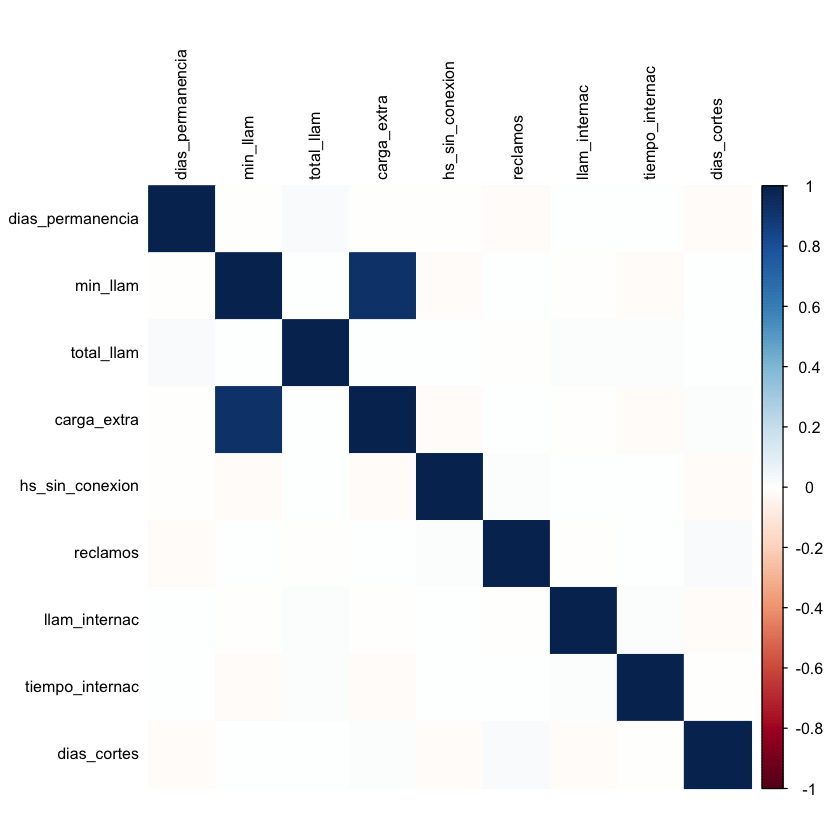

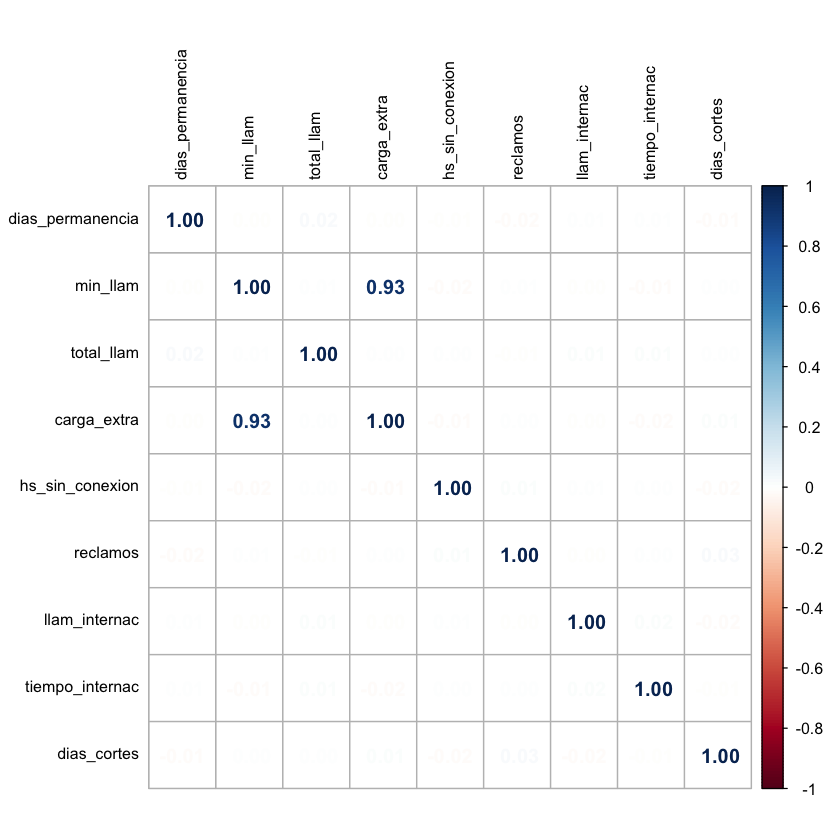

In [15]:
# Se analizan las correlaciones (mide el grado de asociación entre 2 variables de cuantitativas)
varNumericas <- select_if(datos, is.numeric)
correl <- cor(varNumericas)
corrplot(correl, method="color",  tl.col="black", tl.cex=0.8)
corrplot(correl, method="number", tl.col="black", tl.cex=0.8)

* Se observa que las variables **carga_extra** y **min_llam** presentan alta correlación
* La alta correlación entre algunos predictores sugiere que existe multicolinealidad basada en datos
* Esto significa que una de las dos es redundante, porque una no aporta
* Se considera que dos variables cuantitativas están correlacionadas (medida de asociación) cuando los valores de una de ellas varían sistemáticamente con respecto a los valores homónimos de la otra
* Esto  tiene sentido ya que mientras más minutos consuma el usuario más necesidad tendrá de contratar carga extra
* Esta situación será tenida en cuenta más adelante

In [16]:
# Análisis de cada variable con respecto a cancela
myplot <- function(yname) {
  ggplot(data = datos, aes_string(x = "factor(cancela)", y = yname, fill = "factor(cancela)")) +
    geom_boxplot() +
    xlab("cancela") + ylab(yname) +
    theme(legend.position = "none",
          axis.text.x = element_text(),
          axis.ticks = element_line(),
          axis.line = element_line(colour = "royalblue", linewidth = 0.5, linetype = "solid")) +
    scale_fill_brewer(palette = "BuPu")
}

Warning message:
“`aes_string()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`.
ℹ See also `vignette("ggplot2-in-packages")` for more information.”
Warning message:
“<ggplot> %+% x was deprecated in ggplot2 4.0.0.
ℹ Please use <ggplot> + x instead.”


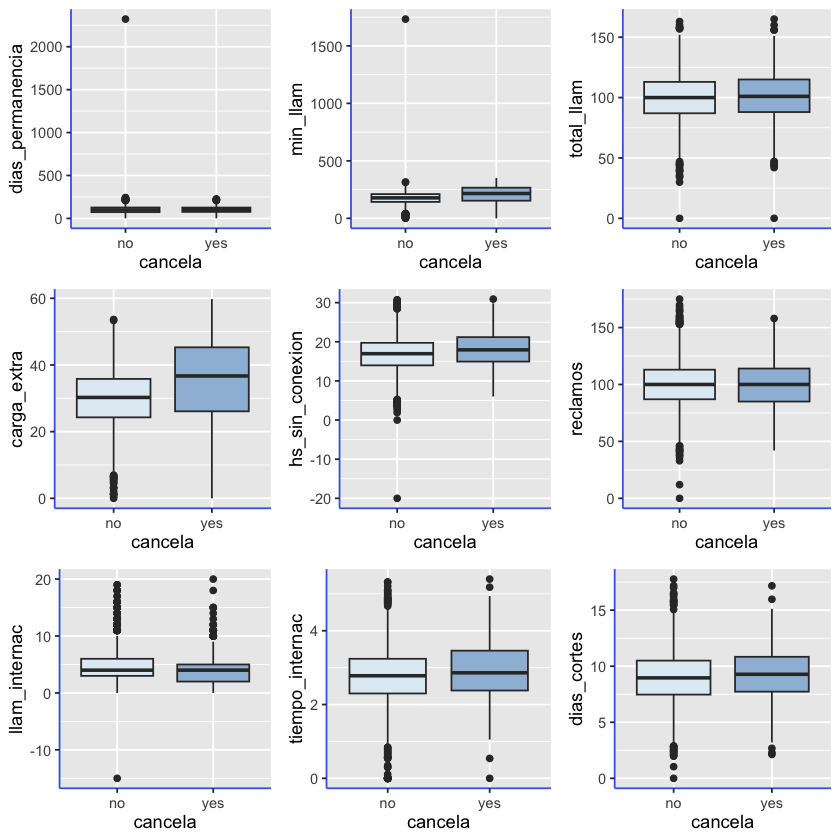

In [17]:
grid.arrange(myplot('dias_permanencia'),
    myplot("min_llam"),
    myplot("total_llam"),
    myplot("carga_extra"),
    myplot("hs_sin_conexion"),
    myplot("reclamos"),
    myplot("llam_internac"),
    myplot("tiempo_internac"),
    myplot("dias_cortes"),
    nrow = 3)

* Boxplot (diagrama caja-bigote)
    * útil para detectar datos atípicos: IQ = Q3 -Q1; valores atípicos > IQ * 1.5 
    * se puede observar la asimetría de la distribución de una variable
    * quedan determinadas medidas de posición: media, mediana, cuartiles, max, min
* Se observa que las variables **hs_sin_conexion** y **llam_internac** presentan datos erróneos, son negativos, inconsistente con la definición de la variable. Se los procede a eliminar
* Se observa que las variables **dias_permanencia** y **min_llam** presentan datos atípicos, muy alejados del resto del set de datos. Se los procede a eliminar

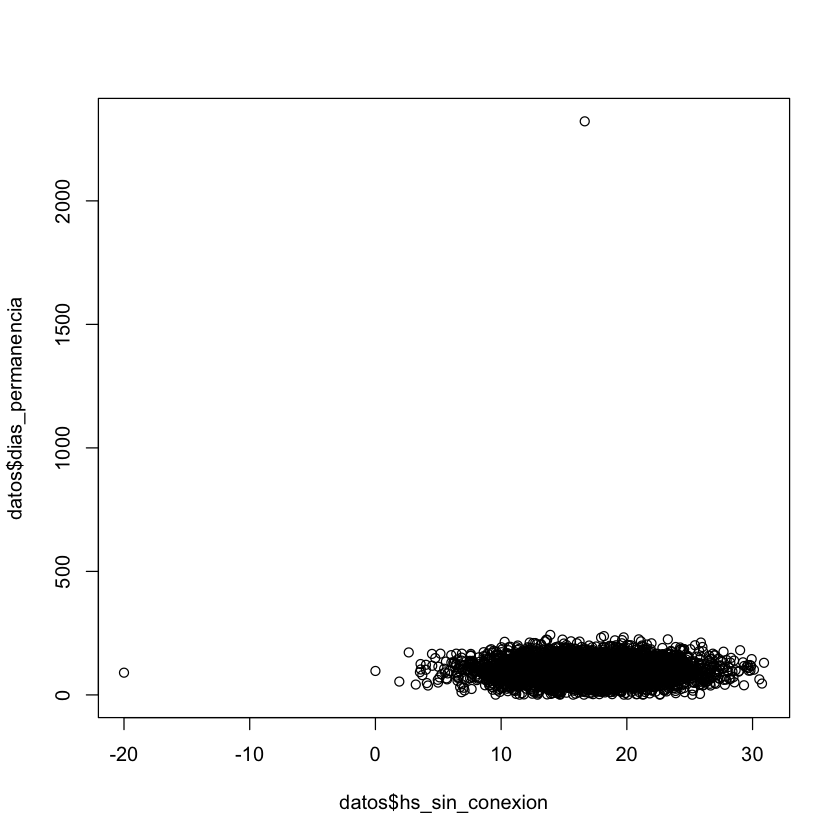

In [18]:
plot(datos$hs_sin_conexion, datos$dias_permanencia)

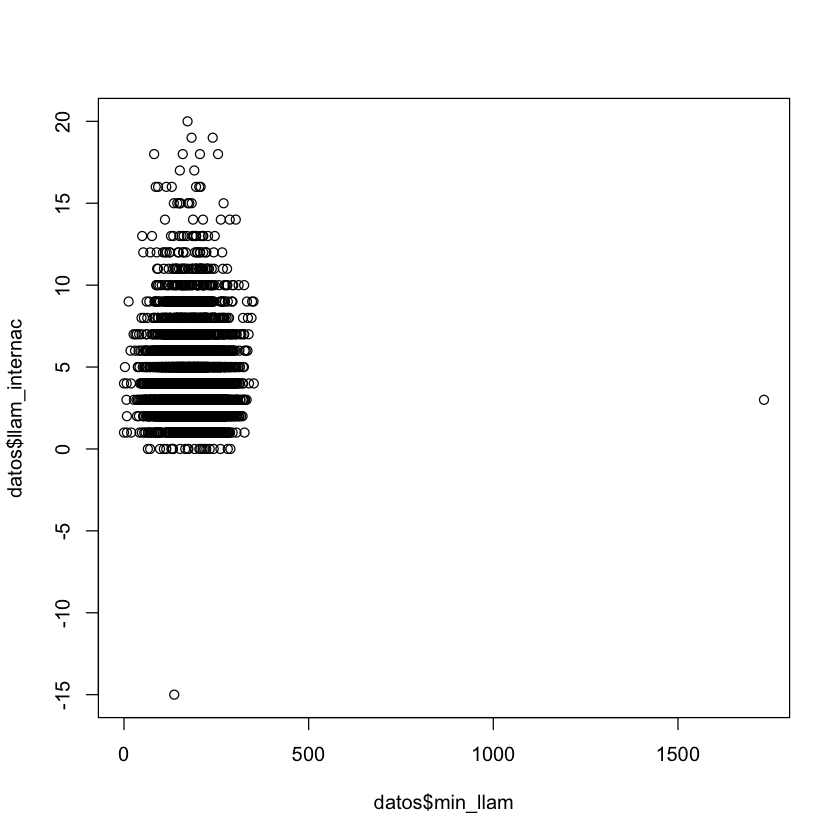

In [19]:
plot(datos$min_llam, datos$llam_internac)

In [20]:
# Se eliminan los outliers detectados
datos <- datos[-which(datos$min_llam > 1000), ]
datos <- datos[-which(datos$llam_internac < -5), ]
datos <- datos[-which(datos$dias_permanencia > 1000), ]
datos <- datos[-which(datos$hs_sin_conexion < -10), ]

In [21]:
summary(datos)

 dias_permanencia packtv        min_llam       total_llam   carga_extra   
 Min.   :  1.0    no :3674   Min.   :  0.0   Min.   :  0   Min.   : 0.00  
 1st Qu.: 73.0    yes:1321   1st Qu.:143.7   1st Qu.: 87   1st Qu.:24.43  
 Median :100.0               Median :180.1   Median :100   Median :30.62  
 Mean   :100.2               Mean   :180.3   Mean   :100   Mean   :30.65  
 3rd Qu.:127.0               3rd Qu.:216.2   3rd Qu.:113   3rd Qu.:36.75  
 Max.   :243.0               Max.   :351.5   Max.   :165   Max.   :59.76  
 hs_sin_conexion    reclamos      llam_internac    tiempo_internac
 Min.   : 0.00   Min.   :  0.00   Min.   : 0.000   Min.   :0.000  
 1st Qu.:14.14   1st Qu.: 87.00   1st Qu.: 3.000   1st Qu.:2.300  
 Median :17.09   Median :100.00   Median : 4.000   Median :2.780  
 Mean   :17.06   Mean   : 99.91   Mean   : 4.435   Mean   :2.771  
 3rd Qu.:19.90   3rd Qu.:113.00   3rd Qu.: 6.000   3rd Qu.:3.240  
 Max.   :30.91   Max.   :175.00   Max.   :20.000   Max.   :5.400  
  dias

## 2. Ajuste de Modelos

In [22]:
# Conjunto de entrenamiento y test
set.seed(0123)
index <- createDataPartition(datos$cancela, p = 0.7, list = FALSE)
train <- datos[index, ]
test <- datos[-index, ]

In [23]:
# Cantidad de casos en conjunto train (entrenamiento)
nrow(train)

[1] 3497

In [24]:
# Cantidad de casos en conjunto test (validación)
nrow(test)

[1] 1498

In [25]:
# Total de casos
nrow(datos)

[1] 4995

* Se separó el conjunto de datos original que contaba con 4995 observaciones en dos conjuntos de datos: un conjunto **train** (entrenamiento) con **3497** observaciones y otro conjunto **test** (validación) con **1498**
* La separación se realizó en forma aleatoria con la proporción **70/30**

### Modelos de regresión logística

* Es una técnica estadística para predecir la probabilidad de un evento categórico (como "sí" o "no") en función de una o más variables independientes
* Se utiliza cuando la variable de resultado es binaria o categórica y puede ser una variable de elección múltiple, y emplea una función sigmoidea (o logística) que "aprieta" la salida del modelo para que se ajuste a un rango entre 0 y 1, representando una probabilidad
* Se usa para:
    * **Análisis de clasificación**: es útil para clasificar datos en una de dos o más categorías 
    * **Predicción**: permite predecir la probabilidad de que ocurra un evento específico 

#### mod_full: todas las variables

In [26]:
# Se ajustó un mod_full con todas las variables
# glm: la regresión logística es un tipo de GLM (Modelos Lineales Generalizados) que utiliza la función logit como función de enlace. 
mod_full <- glm(formula = cancela ~ ., data = train, family = "binomial")
summary(mod_full)


Call:
glm(formula = cancela ~ ., family = "binomial", data = train)

Coefficients:
                   Estimate Std. Error z value Pr(>|z|)    
(Intercept)      -6.375e+00  5.725e-01 -11.136  < 2e-16 ***
dias_permanencia  2.170e-03  1.285e-03   1.689  0.09118 .  
packtvyes        -9.478e-01  1.384e-01  -6.850 7.41e-12 ***
min_llam          4.659e+00  3.017e+00   1.544  0.12251    
total_llam        2.789e-04  2.534e-03   0.110  0.91238    
carga_extra      -2.734e+01  1.775e+01  -1.540  0.12346    
hs_sin_conexion   7.713e-02  1.201e-02   6.420 1.36e-10 ***
reclamos         -1.403e-03  2.551e-03  -0.550  0.58233    
llam_internac    -6.956e-02  2.213e-02  -3.143  0.00167 ** 
tiempo_internac   3.093e-01  6.873e-02   4.500 6.81e-06 ***
dias_cortes       5.677e-02  2.194e-02   2.587  0.00967 ** 
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

(Dispersion parameter for binomial family taken to be 1)

    Null deviance: 2851.9  on 3496  degrees of freedom
Residual devian

#### modelo1

In [27]:
# Modelo1: seleccionando con step sobre todas las variables disponibles
# Obj: encontrar el modelo más simple y efectivo que explique la relación entre las variables predictoras y 
# la variable de respuesta
# Se parte de un modelo completo que contiene todas las variables predictoras y se elimina iterativamente 
# las variables insignificantes
modelo1 <- step(mod_full, direction = "backward", trace = F)
summary(modelo1)


Call:
glm(formula = cancela ~ dias_permanencia + packtv + min_llam + 
    carga_extra + hs_sin_conexion + llam_internac + tiempo_internac + 
    dias_cortes, family = "binomial", data = train)

Coefficients:
                   Estimate Std. Error z value Pr(>|z|)    
(Intercept)       -6.484939   0.453991 -14.284  < 2e-16 ***
dias_permanencia   0.002182   0.001284   1.700  0.08919 .  
packtvyes         -0.947711   0.138371  -6.849 7.43e-12 ***
min_llam           4.688378   3.016541   1.554  0.12013    
carga_extra      -27.509685  17.744343  -1.550  0.12106    
hs_sin_conexion    0.077043   0.012013   6.413 1.42e-10 ***
llam_internac     -0.069383   0.022123  -3.136  0.00171 ** 
tiempo_internac    0.308696   0.068682   4.495 6.97e-06 ***
dias_cortes        0.056661   0.021945   2.582  0.00982 ** 
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

(Dispersion parameter for binomial family taken to be 1)

    Null deviance: 2851.9  on 3496  degrees of freedom
Residual d

* Se ajustó un modelo **modelo1** con todas las variables y con el método Stepwise Backward (Selección hacia Atrás). Se seleccionó el mejor modelo que contiene las siguientes variables significativas:
    * packtv
    * hs_sin_conexion
    * llam_internac
    * tiempo_internac
    * dias_cortes
* **modelo1: cancela ~ dias_permanencia + packtv + min_llam + carga_extra + hs_sin_conexion + llam_internac + tiempo_internac + dias_cortes**
* Comparando contra el **mod_full**, son modelos muy similares en cuanto a la significancia de variables, devianza y el valor de AIC
    * **Desvianza** mide qué tan bien se ajusta el modelo
    * **AIC** (Akaike Information Criterion) permite comparar modelos tomando en cuenta tanto el ajuste como la complejidad (número de parámetros). Penaliza modelos más complejos para evitar sobreajuste
* Optamos por el **modelo1** por ser más simple

#### mod_num: con variables numéricas

In [28]:
variables_numericas = colnames(select_if(datos, is.numeric))
formula = paste('cancela ~', paste(variables_numericas, collapse = '+'))
mod_num = glm(formula, data = train, family = "binomial")
summary(mod_num)


Call:
glm(formula = formula, family = "binomial", data = train)

Coefficients:
                   Estimate Std. Error z value Pr(>|z|)    
(Intercept)      -6.385e+00  5.658e-01 -11.284  < 2e-16 ***
dias_permanencia  2.165e-03  1.276e-03   1.696  0.08983 .  
min_llam          4.819e+00  2.991e+00   1.611  0.10719    
total_llam        8.110e-05  2.511e-03   0.032  0.97423    
carga_extra      -2.828e+01  1.760e+01  -1.607  0.10804    
hs_sin_conexion   7.355e-02  1.191e-02   6.174 6.67e-10 ***
reclamos         -1.403e-03  2.532e-03  -0.554  0.57956    
llam_internac    -6.659e-02  2.190e-02  -3.041  0.00236 ** 
tiempo_internac   2.953e-01  6.810e-02   4.336 1.45e-05 ***
dias_cortes       5.198e-02  2.166e-02   2.400  0.01641 *  
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

(Dispersion parameter for binomial family taken to be 1)

    Null deviance: 2851.9  on 3496  degrees of freedom
Residual deviance: 2631.0  on 3487  degrees of freedom
AIC: 2651

Number of Fis

#### modelo2

In [29]:
# Modelo2: seleccionando con step sobre todas las variables numéricas disponibles
modelo2 <- step(mod_num, direction = "backward", trace = F)
summary(modelo2)


Call:
glm(formula = cancela ~ dias_permanencia + min_llam + carga_extra + 
    hs_sin_conexion + llam_internac + tiempo_internac + dias_cortes, 
    family = "binomial", data = train)

Coefficients:
                   Estimate Std. Error z value Pr(>|z|)    
(Intercept)       -6.513933   0.447977 -14.541  < 2e-16 ***
dias_permanencia   0.002176   0.001275   1.707  0.08791 .  
min_llam           4.836184   2.991094   1.617  0.10591    
carga_extra      -28.380175  17.594617  -1.613  0.10674    
hs_sin_conexion    0.073429   0.011908   6.166 7.00e-10 ***
llam_internac     -0.066419   0.021891  -3.034  0.00241 ** 
tiempo_internac    0.294722   0.068054   4.331 1.49e-05 ***
dias_cortes        0.051859   0.021660   2.394  0.01665 *  
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

(Dispersion parameter for binomial family taken to be 1)

    Null deviance: 2851.9  on 3496  degrees of freedom
Residual deviance: 2631.3  on 3489  degrees of freedom
AIC: 2647.3

Number of F

* Considerando solo las variables numéricas se propone el **modelo2**:
    * cancela ~ dias_permanencia + min_llam + carga_extra + hs_sin_conexion + llam_internac + tiempo_internac + dias_cortes
* Comparando contra el modelo1, son modelos muy similares en cuanto a la significancia de variables, la devianza pero el valor de AIC es mejor (menor) en modelo1
* El modelo1 parece ser superior al modelo2. Claramente el haber eliminado la variable categórica **packtv** (que es altamente significativa en el modelo1) no fue una buena decisión

#### modelo3: con variables significativas del modelo1

In [30]:
# Modelo3: se ajusto un modelo con las variables significativas del modelo1
modelo3 = glm(cancela ~ packtv + hs_sin_conexion + llam_internac + tiempo_internac + dias_cortes, data = train, family = "binomial")
summary(modelo3)


Call:
glm(formula = cancela ~ packtv + hs_sin_conexion + llam_internac + 
    tiempo_internac + dias_cortes, family = "binomial", data = train)

Coefficients:
                Estimate Std. Error z value Pr(>|z|)    
(Intercept)     -3.90462    0.36852 -10.596  < 2e-16 ***
packtvyes       -0.90712    0.13565  -6.687 2.27e-11 ***
hs_sin_conexion  0.07276    0.01171   6.211 5.25e-10 ***
llam_internac   -0.06339    0.02149  -2.950  0.00318 ** 
tiempo_internac  0.26942    0.06711   4.015 5.96e-05 ***
dias_cortes      0.05847    0.02159   2.708  0.00676 ** 
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

(Dispersion parameter for binomial family taken to be 1)

    Null deviance: 2851.9  on 3496  degrees of freedom
Residual deviance: 2732.7  on 3491  degrees of freedom
AIC: 2744.7

Number of Fisher Scoring iterations: 5


#### Análisis de los 4 modelos con AIC

In [31]:
# Se comparan modelos con AIC
AIC(mod_full, modelo1, modelo2, modelo3)

,df,AIC
,<dbl>,<dbl>
mod_full,11,2598.156
modelo1,9,2594.472
modelo2,8,2647.311
modelo3,6,2744.685


* Un AIC más bajo indica un mejor modelo comparativamente
* Según la métrica AIC, el **modelo1** es el que **mejor** se ajusta a los datos (mejor equilibrio) y el de menor complejidad (más parsimonioso)

#### Análisis de devianzas con ANOVA

In [32]:
# Se comparan modelos con devianzas
anova(mod_full, modelo1, modelo2, modelo3)

,Resid. Df,Resid. Dev,Df,Deviance,Pr(>Chi)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,3486,2576.156,NA,NA,NA
2,3488,2576.472,-2,-0.3154573,8.540815e-01
3,3489,2631.311,-1,-54.8392108,1.308049e-13
4,3491,2732.685,-2,-101.3738503,9.703940e-23


* ANOVA se utiliza para comparar la bondad de ajuste de varios modelos anidados (es decir, modelos donde uno es un subconjunto del otro). 
* Al realizar la comparación de devianzas utilizando ANOVA en los 4 modelos se observa:
    * Orden de la comparación: mod_full, modelo1, modelo2, modelo3
    * **Linea N°2 - mod_full vs modelo1**: La devianza residual del modelo1 es levemente mayor pero NO es estadisticamente significativa esa diferencia (p-valor muy alto). El modelo1 es preferible por su parsimonia
    * **Linea N°3 - modelo1 vs modelo2**: La devianza residual del modelo2 es bastante mayor y esa diferencia es altamente signicativa (p-valor menor a 0.05). Se mantiene modelo1 como el mejor
    * **Linea N°4 - modelo2 vs modelo3**: La devianza residual del modelo3 es bastante mayor y esa diferencia es altamente signicativa (p-valor menor a 0.05). Entre ambos, es mejor el modelo2
* El **modelo1** es el más recomendable en base a la bondad de ajuste, además es más simple que el mod_full (que excluye algunas variables no significativas)

#### Análisis de Pseudo R2

In [33]:
#Pseudo R2 - Se toma el modelo que tenga las métricas más altas
pr2_results <- data.frame(PseudoR2(mod_full, c("CoxSnell", "Nagel")), PseudoR2(modelo1, c("CoxSnell", "Nagel")), PseudoR2(modelo2, c("CoxSnell", "Nagel")), 
PseudoR2(modelo3, c("CoxSnell", "Nagel")))
knitr::kable(pr2_results, digits = 5, caption = "Comparación de Métricas Pseudo R2")



Table: Comparación de Métricas Pseudo R2

|           | PseudoR2.mod_full..c..CoxSnell....Nagel...| PseudoR2.modelo1..c..CoxSnell....Nagel...| PseudoR2.modelo2..c..CoxSnell....Nagel...| PseudoR2.modelo3..c..CoxSnell....Nagel...|
|:----------|------------------------------------------:|-----------------------------------------:|-----------------------------------------:|-----------------------------------------:|
|CoxSnell   |                                    0.07583|                                   0.07575|                                   0.06114|                                   0.03352|
|Nagelkerke |                                    0.13599|                                   0.13584|                                   0.10964|                                   0.06012|

* Se utiliza para calcular y comparar los coeficientes de determinación pseudo-R² de Cox & Snell y de Nagelkerke, donde:
    * el de Cox & Snell es la versión base y
    * el de Nagelkerke es una versión ajustada que alcanza el rango completo de 0 a 1, ofreciendo una interpretación más completa
* El Pseudo-R2 proporciona una forma de evaluar qué tan bien un modelo explica la variabilidad de la variable de resultado cuando la variable dependiente es categórica. Esta medida es crucial para los investigadores y analistas de datos que necesitan determinar la efectividad de sus modelos predictivos, especialmente cuando se trata de resultados binarios o multinomiales
* El **modelo1** es el que muestra las métricas más alta, se refuerza las conclusiones obtenidas anteriormente con anova
* Valores más altos de Pseudo-R2 indican un mejor ajuste del modelo a los datos

#### Test de Hosmer-Lemeshow

In [34]:
hoslem.test(mod_full$y, fitted(mod_full))
hoslem.test(modelo1$y, fitted(modelo1))
hoslem.test(modelo2$y, fitted(modelo2))
hoslem.test(modelo3$y, fitted(modelo3))


	Hosmer and Lemeshow goodness of fit (GOF) test

data:  mod_full$y, fitted(mod_full)
X-squared = 261.11, df = 8, p-value < 2.2e-16



	Hosmer and Lemeshow goodness of fit (GOF) test

data:  modelo1$y, fitted(modelo1)
X-squared = 264.89, df = 8, p-value < 2.2e-16



	Hosmer and Lemeshow goodness of fit (GOF) test

data:  modelo2$y, fitted(modelo2)
X-squared = 214.83, df = 8, p-value < 2.2e-16



	Hosmer and Lemeshow goodness of fit (GOF) test

data:  modelo3$y, fitted(modelo3)
X-squared = 15.332, df = 8, p-value = 0.053


* La prueba de **Hosmer-Lemeshow** es una prueba estadística de bondad de ajuste utilizada para evaluar la calidad de un modelo de regresión logística, especialmente en la predicción de riesgos. Mide si las tasas de eventos observadas en subgrupos de datos coinciden con las tasas esperadas predichas por el modelo, utilizando una prueba de chi-cuadrado. Un valor de p > 0.05 generalmente indica que el modelo se ajusta bien a los datos, mientras que un valor de p < 0.05 sugiere un mal ajuste del modelo. 
* Las hipótesis del Test de Hosmer-Lemeshow son:
    * H0: el modelo ajusta los datos
    * H1: el modelo no ajusta los datos
* Este test indica qué tan confiable es el modelo para predecir la probabilidad real de que un cliente cancele 
* Para el **mod_full**, **modelo1** y **modelo2** se obtuvo un p-valor muy pequeño, se rechaza H0. El modelo no se ajusta bien a los datos
* El **modelo3** da un mejor valor de ajuste con respecto a los otros modelos (levemente superior a 0.05) pero, basandonos en los resultados de los tests anteriores, tomamos la decisión de mantener el modelo1
* Cabe aclarar que el ajuste de modelos y los test de bondad de ajuste se realizaron con el conjunto de datos que incluía los outliers y luego se repitieron sin los outliers. En ambos casos los resultados fueron muy similares, por lo que se optó continuar con el conjunto de datos sin los outliers

### Análisis del modelo elegido

* De acuerdo al análisis anterior, se ha elegido el **modelo1**
* **Fórmula**: cancela \~ dias_permanencia + packtv + min_llam + carga_extra + hs_sin_conexion + llam_internac + tiempo_internac + dias_cortes

#### Variables significativas

* Según el test de Wald, las **variables más significativas** son: 
    * packtv (categórica)
    * hs_sin_conexion
    * llam_internac
    * tiempo_internac
    * dias_cortes
* El test de Wald es una prueba estadística que se utiliza para evaluar si los parámetros estimados en un modelo estadístico difieren significativamente de los valores hipotéticos bajo la hipótesis nula

#### Test de bondad de ajuste

* Se hizo el test de bondad de ajuste con ANOVA, comparando los 4 modelos en evaluación
* Se llegó a la conclusión de que el **modelo1** es el modelo estadístico que mejor se ajusta al conjunto de entrenamiento.
* Si bien, no es el modelo con menor devianza residual (variabilidad que no hay sido explicada por el modelo), es el más equilibrado (más parsimonioso)
* Además la diferencia de devianza con el mod_full no es estadísticamente significativa.
* Cabe destacar que el test de Hosmer-Lemeshow indica que el modelo mejor calibrado para predecir la probabilidad de que un cliente cancele es el modelo3, sin embargo, por el resultado de los otros tests, se decide mantener el modelo1

#### Interpretación de coeficiente

In [35]:
summary(modelo1)


Call:
glm(formula = cancela ~ dias_permanencia + packtv + min_llam + 
    carga_extra + hs_sin_conexion + llam_internac + tiempo_internac + 
    dias_cortes, family = "binomial", data = train)

Coefficients:
                   Estimate Std. Error z value Pr(>|z|)    
(Intercept)       -6.484939   0.453991 -14.284  < 2e-16 ***
dias_permanencia   0.002182   0.001284   1.700  0.08919 .  
packtvyes         -0.947711   0.138371  -6.849 7.43e-12 ***
min_llam           4.688378   3.016541   1.554  0.12013    
carga_extra      -27.509685  17.744343  -1.550  0.12106    
hs_sin_conexion    0.077043   0.012013   6.413 1.42e-10 ***
llam_internac     -0.069383   0.022123  -3.136  0.00171 ** 
tiempo_internac    0.308696   0.068682   4.495 6.97e-06 ***
dias_cortes        0.056661   0.021945   2.582  0.00982 ** 
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

(Dispersion parameter for binomial family taken to be 1)

    Null deviance: 2851.9  on 3496  degrees of freedom
Residual d

* **Odds ratio (OR)**: compara chances de los que tienen factor (var independiente) vs los que no
    * OR = (SS / SN) / (NS / NN)
    * OR = 1 => F no representa riesgo
    * OR > 1 => F es dañino
    * OR < 1 => F es protección

| Variables           | Interpretación                                                                              | Odds ratio        |
| --                  | --                                                                                          | --                |
| **packtv**          | indica que tener el pack de tv contratado (packtv = yes) reduce la probabilidad de cancelar | exp(-0.94) = 0.39 |
| **hs_sin_conexion** | Indica que por cada hora sin conexión aumenta la probabilidad de cancelar                   | exp(0.07) = 1.08  |
| **llam_internac**   | Indica que por cada llamada internacional realizada disminuye la probabilidad de cancelar   | exp(-0.06) = 0.93 |
| **tiempo_internac** | Indica que si hay más tiempo de llamada internacional aumenta la probabilidad de cancelar   | exp(0.30) = 1.36  |
| **dias_cortes**     | Indica que más días de cortes aumenta la probabilidad de cancelar                           | exp(0.05) = 1.06  |

* Los clientes que tienen el pack tv contratado, realizan mas llamadas internacionales y poco tiempo de llamadas internacionales, tienen menos chances de cancelar
* Los clientes que tienen más horas sin conexión, más tiempo en llamadas internacionales y más días de corte, son los que tienen más chances de cancelar

#### Análisis de multicolinealidad (VIF)

In [36]:
vif(modelo1)

dias_permanencia           packtv         min_llam      carga_extra 
    1.001381e+00     1.006712e+00     9.229671e+06     9.229667e+06 
 hs_sin_conexion    llam_internac  tiempo_internac      dias_cortes 
    1.007690e+00     1.002930e+00     1.005560e+00     1.003045e+00

* **VIF (Factor de Inflación de la Varianza)**: es un método para detectar colinealidad entre las variables regresoras
* Este factor se calcula para cada variable regresora
    * VIF > 10 => indicio fuerte de multicolinealidad
    * 5 < VIF < 10 => indicio de moderada multicolinealidad
    * VID < 5 => indicio de baja multicolinealidad
* Se observa una alta multicolinealidad en las variables **min_llam** y **carga_extra**, en parte era esperado por el análisis de correlación que realizamos al principio
* Se procedió a ajustar dos nuevo modelos separando esas variables juntas para comparar el comportamiento

In [37]:
modelo1_sin_min_llam <- glm(cancela ~ dias_permanencia + packtv + carga_extra + hs_sin_conexion + llam_internac + tiempo_internac + dias_cortes, data = train, family = "binomial")
modelo1_sin_carga_extra <- glm(cancela ~ dias_permanencia + packtv + min_llam + hs_sin_conexion + llam_internac + tiempo_internac + dias_cortes, data = train, family = "binomial")

In [40]:
AIC(modelo1, modelo1_sin_min_llam, modelo1_sin_carga_extra)

,df,AIC
,<dbl>,<dbl>
modelo1,9,2594.472
modelo1_sin_min_llam,8,2594.889
modelo1_sin_carga_extra,8,2594.877


In [41]:
anova(modelo1, modelo1_sin_min_llam, modelo1_sin_carga_extra)

,Resid. Df,Resid. Dev,Df,Deviance,Pr(>Chi)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,3488,2576.472,NA,NA,NA
2,3489,2578.889,-1,-2.41766420,0.1199737
3,3489,2578.877,0,0.01209257,NA


In [42]:
vif(modelo1_sin_carga_extra)

dias_permanencia           packtv         min_llam  hs_sin_conexion 
        1.001351         1.006711         1.009761         1.007551 
   llam_internac  tiempo_internac      dias_cortes 
        1.002932         1.005405         1.003021

* Analizando con AIC y ANOVA **modelo1** con **modelo1_sin_min_llam** se vizualiza que la devianza aumenta en 2.41 unidades y el p-valor no es estadisticamente significativo
* Esto indica que eliminar esa variable no empeora significativamente el ajuste, por lo que esa variable puede ser prescindible
* Entre los modelos: **modelo1_sin_min_llam** y **modelo1_sin_carga_extra** no hay diferencia en la devianza, por lo que sería lo mismo elegir cualquiera de esos modelos
* Finalmente, elegimos el **modelo1_sin_carga_extra** salvando la multicolinalidad y siendo más parsimonioso que el modelo1 original

#### Datos influyentes

* Para detectar posibles puntos influyentes, además de los eliminados al principio, se calcula la distancia de Cook y los hatvalues
* Es necesario detectar la existencia de puntos que pueden influir en la determinación del modelo (si cambian o no los parámetros)
* Outliers (valor atípico) son datos que se apartan mucho de la tendencia general pueden cambiar sustancialmente las estimaciones del modelo
* Si el outlier corresponde a un error de tipeo o un dato mal registradom se lo puede eliminar o corregir

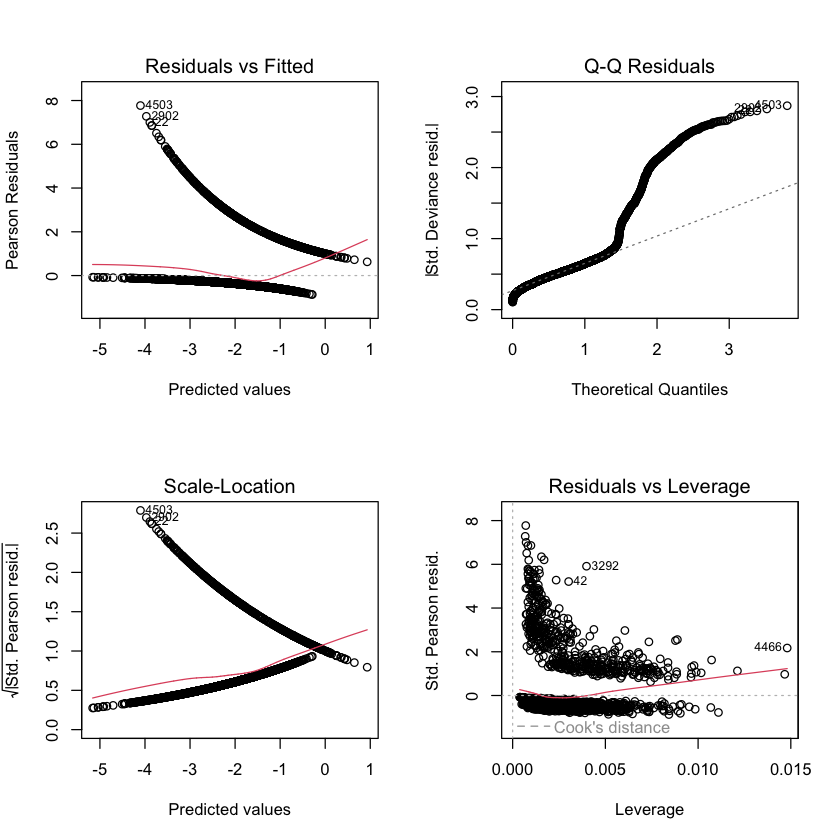

In [43]:
par(mfrow = c(2,2))
plot(modelo1_sin_carga_extra)
par(mfrow = c(1,1))

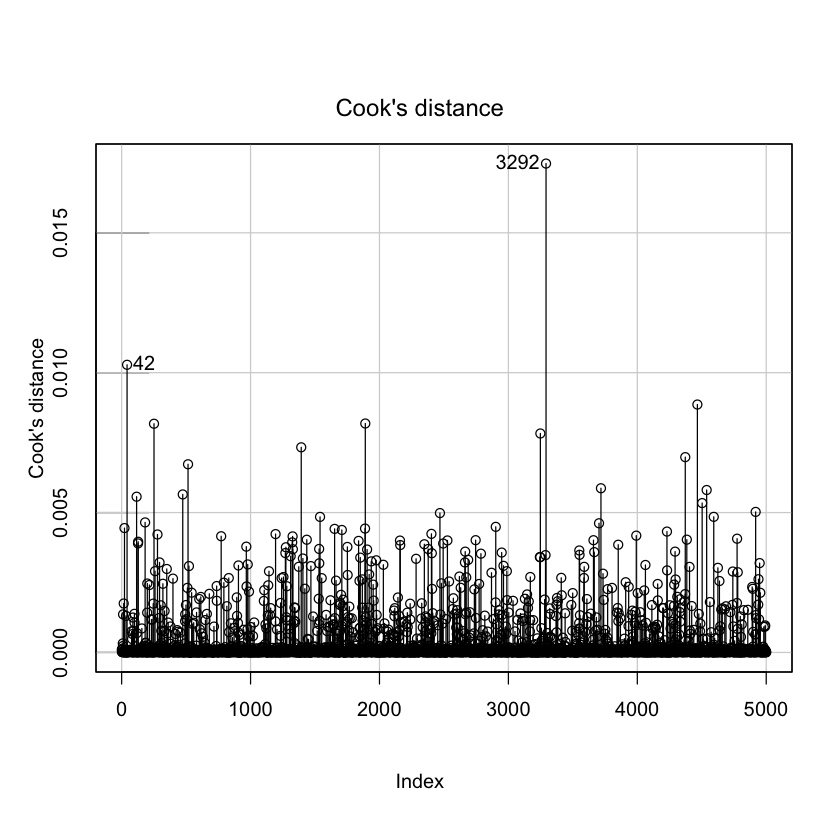

In [44]:
influenceIndexPlot(modelo1_sin_carga_extra, vars = "Cook", id=T, main = "Cook's distance")

* La "distancia de Cook" (o Cook's distance) es una medida estadística que se usa en regresión lineal para identificar puntos de datos que tienen una gran influencia en los coeficientes del modelo de regresión o en los valores predichos, es decir, para detectar valores atípicos o influyentes
* Se calcula como la distancia geométrica entre los valores predichos con y sin una observación específica, y un valor de distancia de Cook alto indica que la eliminación de esa observación podría alterar significativamente el modelo
* No existe un umbral estricto y universal. Sin embargo, se suelen usar reglas generales como:
    * Un valor de distancia de Cook superior a 1 se considera una observación de alta influencia
    * Una distancia de Cook mayor que 0,5 a menudo se considera que merece una investigación
    * En algunos casos, se utiliza un umbral de 4/n, donde 'n' es el número de observaciones
* El umbral es el qf (distribución de Fisher) con n - 2 grados de libertad

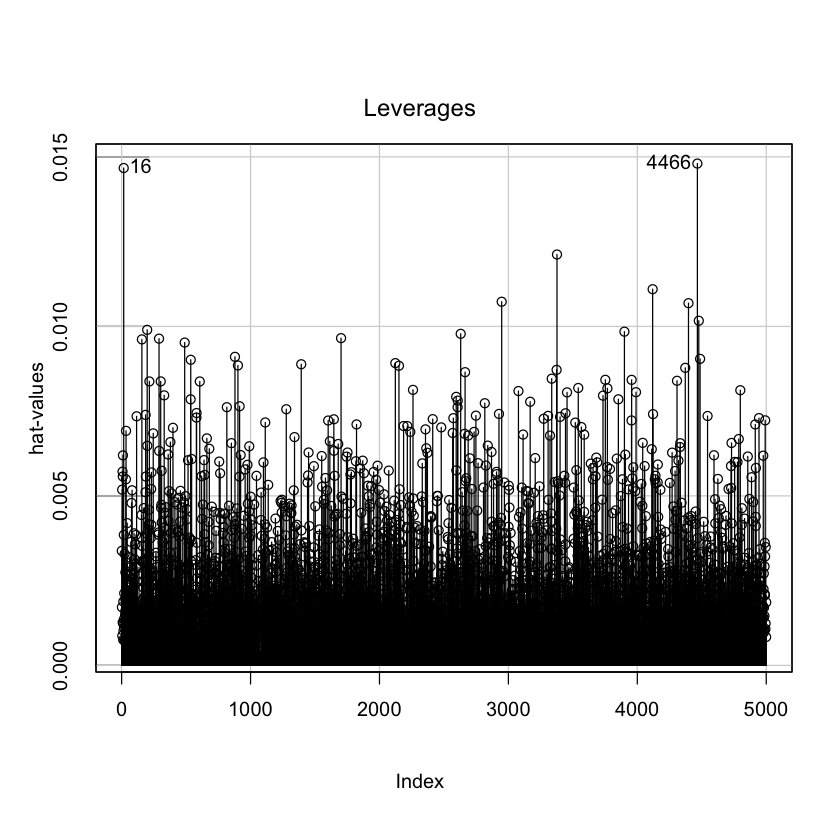

In [45]:
influenceIndexPlot(modelo1_sin_carga_extra, vars = "hat", id=T, main = "Leverages")

* Leverages ("palanca")
* También son puntos influyentes
* Son observaciones: x muy alejadas de la media de las x (en horizontal)
* Afecta a la varianza de los residuos
* Puede ser:
    * **buena**: no altera a la ecuación de la recta, residuo bajo (no muy alejada de la recta)
    * **mala**: residuo ALTO (efecto palanca), cambia la recta y por lo tanto cambia la predicción. Hay que eliminar el punto

* Si bien hay algunos puntos que sobresalen del resto del set de datos, no se consideran muy alejados por lo que se decide dejarlos

## 3. Métodos de clasificación

Se ajustaron modelos de clasificación con los métodos Naive Bayes, KNN y SVM

### Naive Bayes

* Es un algoritmo de **aprendizaje supervisado** basado en el teorema de **Bayes**
* Se utiliza para tareas de clasificación, como la filtración de spam o la clasificación de textos. Es multiclase
* Asume que todos los atributos son independientes entre sí, lo que simplifica enormemente los cálculos de probabilidad, a pesar de que esta suposición raramente se cumpla en el mundo real
* Si se quiere calcular la probabilidad de un evento dado otro, se puede hacer en base a esta fórmula:

$$𝑃(𝐴/𝐵) = \dfrac{𝑃(𝐵/𝐴) 𝑃(𝐴)}{𝑃(𝐵)}$$

1. **Basado en la probabilidad**: el modelo se basa en el teorema de Bayes, que ayuda a calcular la probabilidad de un evento basándose en la probabilidad de otro evento relacionado 
2. **Suposición de independencia**: la clave de Naive Bayes es la suposición de independencia condicional. Esto significa que la presencia de una característica en un dato es completamente independiente de la presencia de otras características, dado que sabemos a qué clase pertenece el dato. Por ejemplo, en un correo electrónico, la presencia de la palabra "gratis" se considera independiente de la presencia de la palabra "oferta", aunque en la realidad no sea así
3. **Cálculo de probabilidades**: para clasificar un nuevo dato, Naive Bayes calcula la probabilidad de que cada una de las clases pueda generar ese dato, basándose en las probabilidades de las características de entrenamiento 
4. **Predicción**: se selecciona la clase que tiene la mayor probabilidad para el nuevo dato

In [46]:
set.seed(0123)
mod_bayes <- naiveBayes(cancela ~ ., data = train, laplace = 0)
mod_bayes


Naive Bayes Classifier for Discrete Predictors

Call:
naiveBayes.default(x = X, y = Y, laplace = laplace)

A-priori probabilities:
Y
       no       yes 
0.8584501 0.1415499 

Conditional probabilities:
     dias_permanencia
Y          [,1]     [,2]
  no   99.70919 39.34381
  yes 103.10505 38.96933

     packtv
Y            no       yes
  no  0.7158561 0.2841439
  yes 0.8565657 0.1434343

     min_llam
Y         [,1]     [,2]
  no  175.3005 49.61967
  yes 206.0251 68.06854

     total_llam
Y          [,1]     [,2]
  no   99.89007 19.78574
  yes 100.15152 20.48558

     carga_extra
Y         [,1]      [,2]
  no  29.80168  8.435332
  yes 35.02463 11.571800

     hs_sin_conexion
Y         [,1]     [,2]
  no  16.86938 4.247311
  yes 18.11040 4.444312

     reclamos
Y          [,1]     [,2]
  no  100.08961 19.84422
  yes  99.76566 19.54103

     llam_internac
Y         [,1]     [,2]
  no  4.500333 2.485982
  yes 4.151515 2.590717

     tiempo_internac
Y         [,1]      [,2]
  no  2.75109

* NB asume que hay más probabilidad de que cancela=no (85.84%) que cancela=si (14.15%).

-   **Analisis de packtv**: P(packtv=yes | Y=no) = 0.283  > El 28% de los que no cancelaron, tenian el packtv.
                            P(packtv=yes | Y=yes) = 0.143 > El 14% de los que cancelaron, tenian el packtv.
    Puede sugerir que tene el packtv está asociado a una menor probabilidad de que cancelen

-   **Analisis de min_llam**: Muestra que la media de minutos de llamada para los que no cancelaron es de 175.28.
                              Muestra que la media de minutos de llamada para los que cancelaron es de 206.02

### KNN - K-Nearest Neighbors (K-Vecinos Más Cercanos)

* Es un algoritmo de **aprendizaje supervisado (se conoce la clase objetivo) no paramétrico (no construye un modelo)** que se usa para tareas de clasificación y regresión. Es simplemente aplicar un algoritmo. Es multiclase
* Su funcionamiento se basa en la idea de que los puntos de datos similares suelen tener etiquetas similares
* Para clasificar un nuevo punto, el algoritmo encuentra los "k" vecinos más cercanos en el conjunto de datos y asigna al nuevo punto la clase más común entre esos vecinos (para clasificación) o el valor promedio (para regresión

1. **Cálculo de distancias**: se calcula la distancia entre el nuevo punto de datos y todos los puntos del conjunto de entrenamiento. La distancia euclidiana es una de las métricas más comunes, aunque existen otras como la distancia de Manhattan o la de Minkowski
2. **Identificación de vecinos**: el algoritmo selecciona los "k" puntos más cercanos al nuevo punto, basándose en la distancia calculada. El valor de "k" es un parámetro que se elige según la complejidad del problema. Se sugiere "k" impar para evitar empates
3. **Asignación de la clase**:
    * **Clasificación**: se elige la clase que más se repite entre los "k" vecinos más cercanos
    * **Regresión**: se toma el valor promedio de los "k" vecinos más cercanos para predecir el valor del nuevo punto
4. Las variables deben ser todas numéricas, aunque pueden usarse categóricas convertidas a numéricas ficticiamente (dummies)

Con este algoritmo se hicieron dos entrenamientos, uno eliminando packtv por ser categórica y otro incluyendo packtv utilizando la técnica de dummies

#### Sin packtv

In [47]:
set.seed(0123)
knnEntrenadoNum <- train(cancela ~ . -packtv, 
                      data = train, 
                      method = "knn",  
                      tuneLength = 10, # opcion para decir #valores de k que le pido que pruebe
                      trControl = trainControl(method="cv", number = 5),
                      preProcess = c("center","scale")
)
knnEntrenadoNum

k-Nearest Neighbors 

3497 samples
  10 predictor
   2 classes: 'no', 'yes' 

Pre-processing: centered (9), scaled (9) 
Resampling: Cross-Validated (5 fold) 
Summary of sample sizes: 2798, 2798, 2797, 2798, 2797 
Resampling results across tuning parameters:

  k   Accuracy   Kappa    
   5  0.8644517  0.2150661
   7  0.8690292  0.2098594
   9  0.8707443  0.2088659
  11  0.8707451  0.2008228
  13  0.8707460  0.1924027
  15  0.8704598  0.1788769
  17  0.8698872  0.1670731
  19  0.8681721  0.1513919
  21  0.8687435  0.1572045
  23  0.8693162  0.1567113

Accuracy was used to select the optimal model using the largest value.
The final value used for the model was k = 13.

#### Utilizando dummies e incluyendo la variable packtv

In [48]:
## Se convierte factores en dummies
set.seed(0123)
datos_dummies <- dummy_cols(datos, select_columns = c("packtv"),
                            remove_selected_columns = T, remove_first_dummy = T)
summary(datos_dummies)

 dias_permanencia    min_llam       total_llam   carga_extra    hs_sin_conexion
 Min.   :  1.0    Min.   :  0.0   Min.   :  0   Min.   : 0.00   Min.   : 0.00  
 1st Qu.: 73.0    1st Qu.:143.7   1st Qu.: 87   1st Qu.:24.43   1st Qu.:14.14  
 Median :100.0    Median :180.1   Median :100   Median :30.62   Median :17.09  
 Mean   :100.2    Mean   :180.3   Mean   :100   Mean   :30.65   Mean   :17.06  
 3rd Qu.:127.0    3rd Qu.:216.2   3rd Qu.:113   3rd Qu.:36.75   3rd Qu.:19.90  
 Max.   :243.0    Max.   :351.5   Max.   :165   Max.   :59.76   Max.   :30.91  
    reclamos      llam_internac    tiempo_internac  dias_cortes     cancela   
 Min.   :  0.00   Min.   : 0.000   Min.   :0.000   Min.   : 0.000   no :4288  
 1st Qu.: 87.00   1st Qu.: 3.000   1st Qu.:2.300   1st Qu.: 7.520   yes: 707  
 Median :100.00   Median : 4.000   Median :2.780   Median : 9.020             
 Mean   : 99.91   Mean   : 4.435   Mean   :2.771   Mean   : 9.019             
 3rd Qu.:113.00   3rd Qu.: 6.000   3rd Qu.:3.

In [ ]:
train2 <- datos_dummies[index, ]
test2 <- datos_dummies[-index, ]
knnEntrenado <- train(cancela ~ ., 
                      data = train2, 
                      method = "knn",  
                      tuneLength = 20, # opcion para decir #valores de k que le pido que pruebe
                      trControl = trainControl(method = "cv", number = 5),
                      preProcess = c("center","scale")
)
knnEntrenado

* El algoritmo detectó que un valor de k = 7 (7 vecinos mas cercanos) es el mejor para clasificar casos nuevos
* Se puede observar que la alternativa con dummies tiene una mayor precisión (accuracy 88.96%) y un mejor kappa (0.3485).
* Además, cabe destacar, que ambos obtuvieron un valor de Kappa muy bajo lo cual indica que los datos están desbalanceados en el dataset de entrenamiento, el modelo puede llegar a tener problemas para predecir la clase minoritaria

### SVM (Máquina de Vectores de Soporte)

* Es un algoritmo de **aprendizaje automático supervisado (se conoce la clase)** que se utiliza para clasificación y regresión. Es multiclase
* Objetivo: encontrar el hiperplano óptimo que maximice la distancia entre diferentes clases de datos en un espacio N-dimensional, buscando un límite de decisión que funcione bien incluso con datos no linealmente separables mediante el uso de funciones kernel y vectores de soporte
    * Se busca la recta cuya mínima distancia sea máxima, es decir, que separe BIEN
    * Se elige el de mayor margen de separación: el maximal margin hyperplane
* Se ajusta con un hiperparámetro de tuning **C**
    * Con un C grande se penaliza mucho (0 error)
    * Con un C chico se penaliza poco

1. **Búsqueda del hiperplano**: en esencia, una SVM busca la línea (o plano en dimensiones superiores) que mejor separa (geometricamente) los puntos de datos pertenecientes a diferentes categorías 
2. **Maximización del margen**: esta línea, o hiperplano, se elige de tal forma que maximiza el margen, es decir, la distancia entre ella y los puntos más cercanos de cada clase. Estos puntos cercanos se conocen como vectores de soporte 
3. **Funciones Kernel**: para datos que no se pueden separar linealmente, las SVM utilizan funciones kernel para transformar los datos a un espacio de mayor dimensión, donde pueden volverse linealmente separables. Algunos kernels comunes incluyen el lineal, polinomial y el de base radial (RBF)

Se procede a utilizar los kernel radial, lineal y polinómico para ajustar 3 modelos distintos

In [99]:
set.seed(0123)
svm_radial <- tune("svm", cancela ~ ., 
                 data  = train, 
                 probability = TRUE,
                 kernel = 'radial',
                 ranges = list(cost = c(0.01, 1, 5, 10, 50)))
summary(svm_radial)


Parameter tuning of ‘svm’:

- sampling method: 10-fold cross validation 

- best parameters:
 cost
    5

- best performance: 0.09752681 

- Detailed performance results:
   cost      error dispersion
1  0.01 0.14156365 0.01558496
2  1.00 0.10295866 0.01786551
3  5.00 0.09752681 0.01774139
4 10.00 0.09952190 0.01587156
5 50.00 0.12297503 0.01542591


* **Modelo con kernel radial**: El mejor valor de costo es el 5 con una tasa de error de 9.75%. Eso indica que tiene buena precisión, un poco mayor al 90%

In [100]:
svm_linear <- tune("svm", cancela ~ ., 
                 data = train, 
                 probability = TRUE,
                 kernel = 'linear',
                 ranges = list(cost = c(0.001, 0.01, 1, 5)))
summary(svm_linear)


Parameter tuning of ‘svm’:

- sampling method: 10-fold cross validation 

- best parameters:
  cost
 0.001

- best performance: 0.1415555 

- Detailed performance results:
   cost     error dispersion
1 0.001 0.1415555 0.01230249
2 0.010 0.1415555 0.01230249
3 1.000 0.1415555 0.01230249
4 5.000 0.1415555 0.01230249


* **Modelo con kernel linear**: El mejor valor de costo es 0.001 con una tasa de error de 14.15%
* Lo curioso de este modelo con kernel lineal es que todos los costos tienen la misma tasa de error

In [102]:
svm_polyn <- tune("svm", cancela ~ ., 
                 data = train, 
                 probability = TRUE,
                 kernel = 'polynomial',
                 ranges = list(cost = c(0.01, 1, 5, 10, 50)))
summary(svm_polyn)


Parameter tuning of ‘svm’:

- sampling method: 10-fold cross validation 

- best parameters:
 cost
    5

- best performance: 0.09492427 

- Detailed performance results:
   cost      error dispersion
1  0.01 0.14124355 0.02135606
2  1.00 0.09520999 0.02001386
3  5.00 0.09492427 0.02058664
4 10.00 0.09578223 0.02078089
5 50.00 0.09549652 0.02125668


* **Modelo con kernel polynomial**: El mejor valor de costo es 5 con una tasa de error de 9.4%.

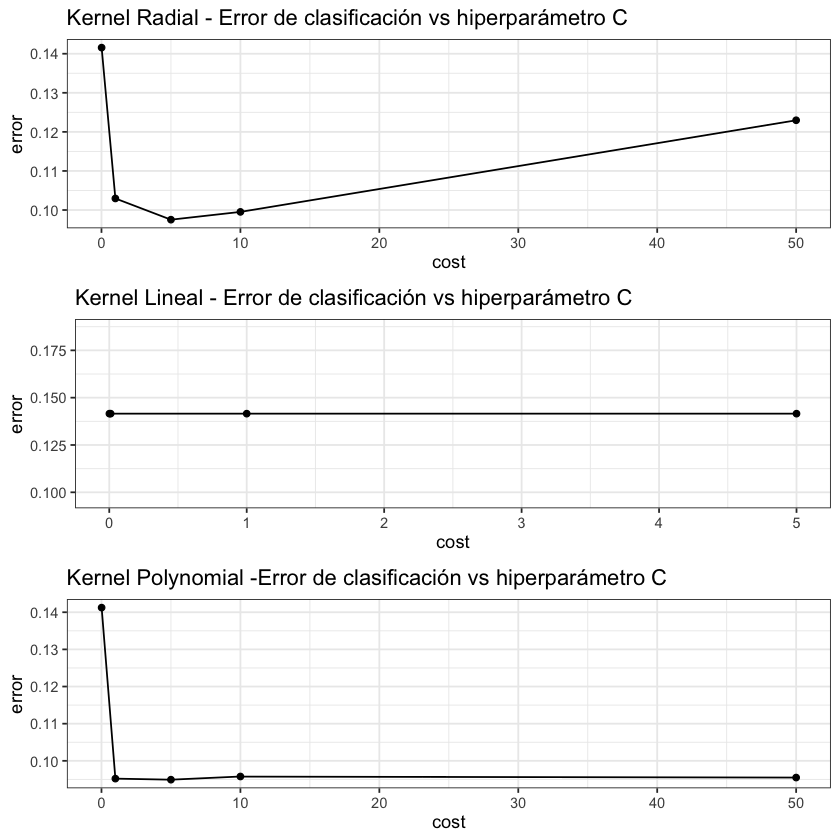

In [103]:
# Se muestra la relación entre errores y costos de cada uno
plot_radial <- ggplot(data = svm_radial$performances, aes(x = cost, y = error)) +
  geom_line() +
  geom_point() +
  labs(title = "Kernel Radial - Error de clasificación vs hiperparámetro C") +
  theme_bw()

plot_linear <- ggplot(data = svm_linear$performances, aes(x = cost, y = error)) +
  geom_line() +
  geom_point() +
  labs(title = "Kernel Lineal - Error de clasificación vs hiperparámetro C") +
  theme_bw()

plot_polyn <- ggplot(data = svm_polyn$performances, aes(x = cost, y = error)) +
  geom_line() +
  geom_point() +
  labs(title = "Kernel Polynomial -Error de clasificación vs hiperparámetro C") +
  theme_bw()

grid.arrange(plot_radial, plot_linear, plot_polyn)

## 4. Evaluación de los modelos en Test

A continuación se procede a probar la capacidad predictiva de los diferentes modelos analizando la matriz de confusión y el área bajo la curva ROC

### Matriz de confusión y AUC

In [105]:
confusion_log <- function(nombre, modelo, test) {
    pred <- predict.glm(modelo, newdata = test, type = "response")
    predi_y <- ifelse(pred >= 0.5, "yes", "no")
    tabla <- table(predi_y, test$cancela)
    print(nombre)
    print(tabla)
    return (confusionMatrix(tabla, positive = "yes"))
}

In [107]:
confusion_bayes <- function(nombre, modelo, test) {
    pred <- predict(modelo, newdata = test, type = "class")
    tabla <- table(pred, test$cancela)
    print(nombre)
    print(tabla)
    return (confusionMatrix(tabla, positive = "yes"))
}

In [108]:
confusion_knn <- function(nombre, modelo, test) {
    pred <- predict(modelo, newdata = test)
    tabla <- table(pred, test$cancela)
    print(nombre)
    print(tabla)
    return (confusionMatrix(tabla, positive = "yes"))
}

In [109]:
confusion_svm <- function(nombre, modelo, test) {
    pred <- predict(modelo, test, type = "class")
    tabla <- table(pred, test$cancela)
    print(nombre)
    print(tabla)
    return (confusionMatrix(tabla, positive = "yes"))
}

In [110]:
area_roc_log <- function(nombre, modelo, test) {
    pred <- predict.glm(modelo, newdata = test, type = "response") 
    predi <- prediction(pred, test$cancela)
    roc  <- performance(predi, measure = "tpr", x.measure = "fpr")
    plot(roc, main = paste("curva ROC ", nombre), colorize = T)
    abline(a = 0, b = 1)
    return (performance(predi, "auc")@y.values)
}

In [111]:
area_roc_bayes <- function(nombre, modelo, test) {
    pred <- predict(modelo, newdata = test, type = "raw")
    predi <- prediction(pred[,2], test$cancela)
    roc <- performance(predi, measure = "tpr", x.measure = "fpr")
    plot(roc, main = paste("curva ROC ", nombre), colorize = T)
    abline(a = 0, b = 1)
    return (performance(predi, "auc")@y.values)
}

In [114]:
area_roc_knn <- function(nombre, modelo, test) {
    pred <- predict(modelo, newdata = test , type = "prob")
    predi <- prediction(pred[,2], test$cancela)
    roc <- performance(predi, measure = "tpr", x.measure = "fpr")
    plot(roc, main = paste("curva ROC ", nombre), colorize = T)
    abline(a = 0, b = 1)
    return (performance(predi, "auc")@y.values)
}

In [112]:
area_roc_svm <- function(nombre, modelo, test) {
    pred <- predict(modelo, test, type = "prob", probability = TRUE)
    predi <- prediction(attr(pred, "probabilities")[,2], test$cancela)
    roc <- performance(predi, measure = "tpr", x.measure = "fpr")
    plot(roc, main = paste("curva ROC SVM ", nombre), colorize = T)
    abline(a = 0, b = 1)
    return (performance(predi, "auc")@y.values)
}

In [113]:
metricas <- function(nombre, conf, area) {
    return (data.frame(
      Model = nombre,
      Accuracy = conf$overall["Accuracy"],
      Sensitivity = conf$byClass["Sensitivity"],
      Specificity = conf$byClass["Specificity"],
      Precision = conf$byClass["Pos Pred Value"],
      Area_ROC  = area[[1]]))
}

In [118]:
metricas_log <- function(nombre, modelo, test) {
    return (metricas(nombre, confusion_log(nombre, modelo, test), area_roc_log(nombre, modelo, test)))    
}

In [119]:
metricas_bayes <- function(nombre, modelo, test) {
    return (metricas(nombre, confusion_bayes(nombre, modelo, test), area_roc_bayes(nombre, modelo, test)))
}

In [120]:
metricas_knn <- function(nombre, modelo, test) {
    return (metricas(nombre, confusion_knn(nombre, modelo, test), area_roc_knn(nombre, modelo, test)))
}

In [121]:
metricas_svm <- function(nombre, modelo, test) {
    return (metricas(nombre, confusion_svm(nombre, modelo, test), area_roc_svm(nombre, modelo, test)))
}

[1] "Regresión"
       
predi_y   no  yes
    no  1286  197
    yes    0   15


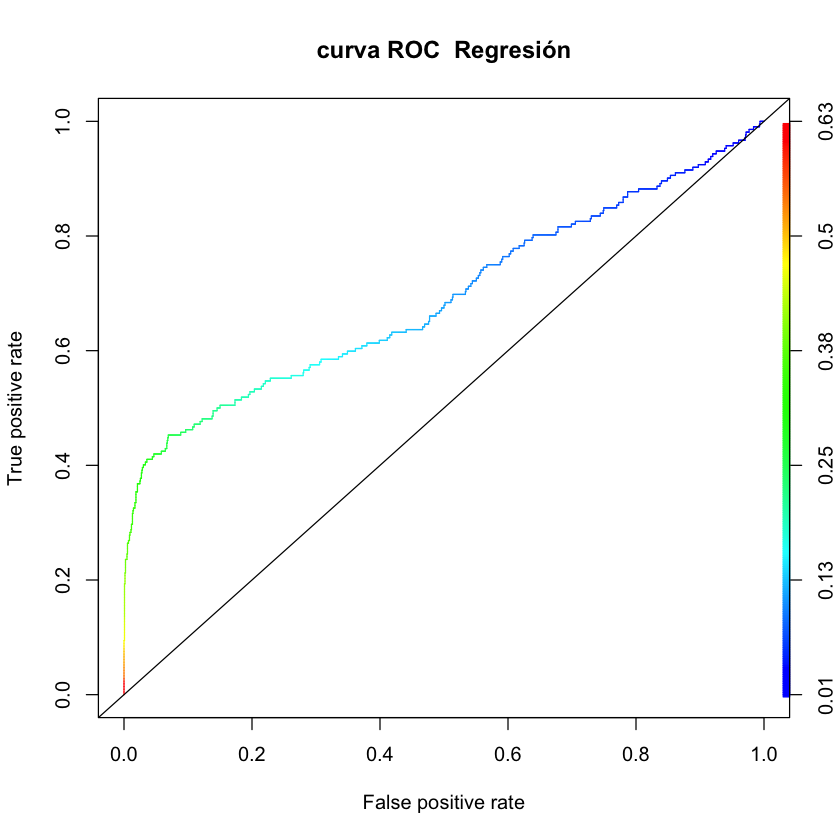

In [128]:
m_modelo1 <- metricas_log("Regresión", modelo1, test)

[1] "Naive Bayes"
     
pred    no  yes
  no  1245  139
  yes   41   73


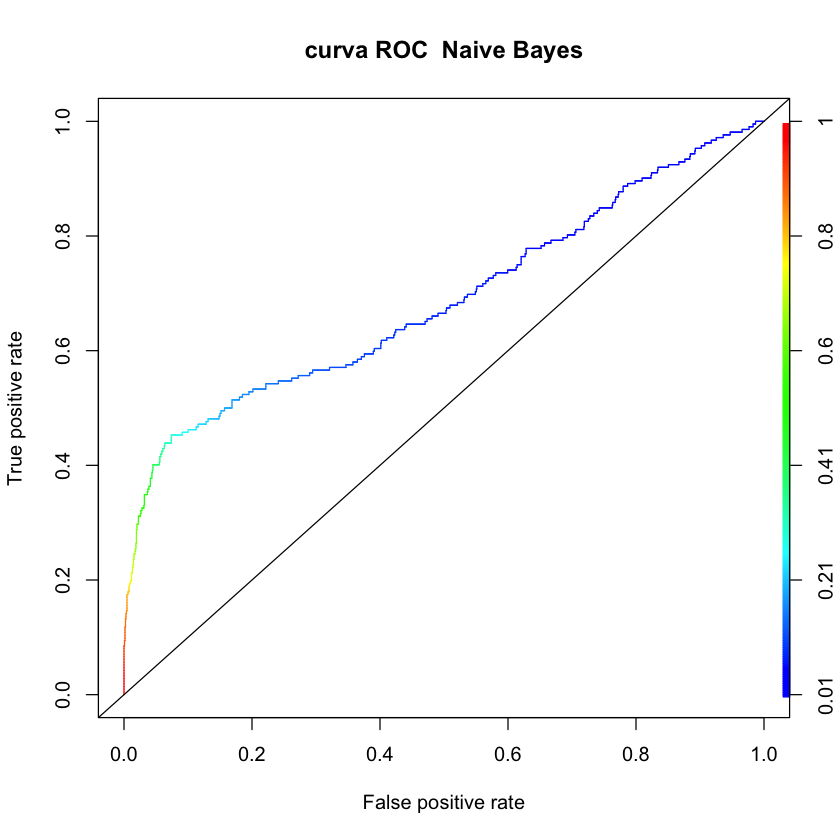

In [129]:
m_bayes <- metricas_bayes("Naive Bayes", mod_bayes, test)

[1] "KNN"
     
pred    no  yes
  no  1280  158
  yes    6   54


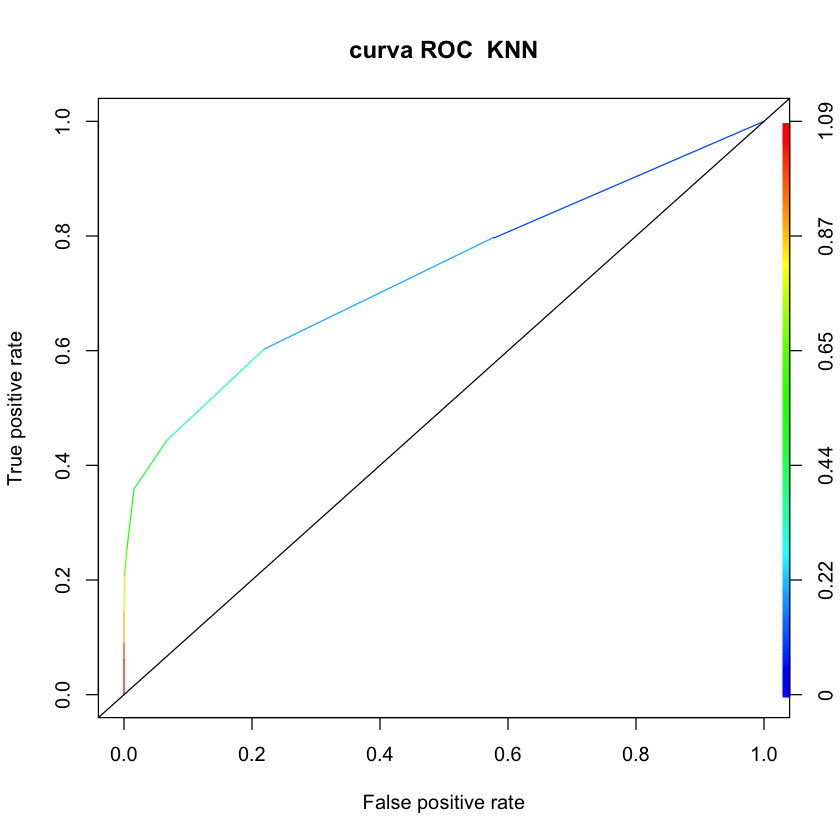

In [130]:
m_knn <- metricas_knn("KNN", knnEntrenado, test2)

[1] "Radial"
     
pred    no  yes
  no  1277  131
  yes    9   81
[1] "Linear"
     
pred    no  yes
  no  1286  212
  yes    0    0


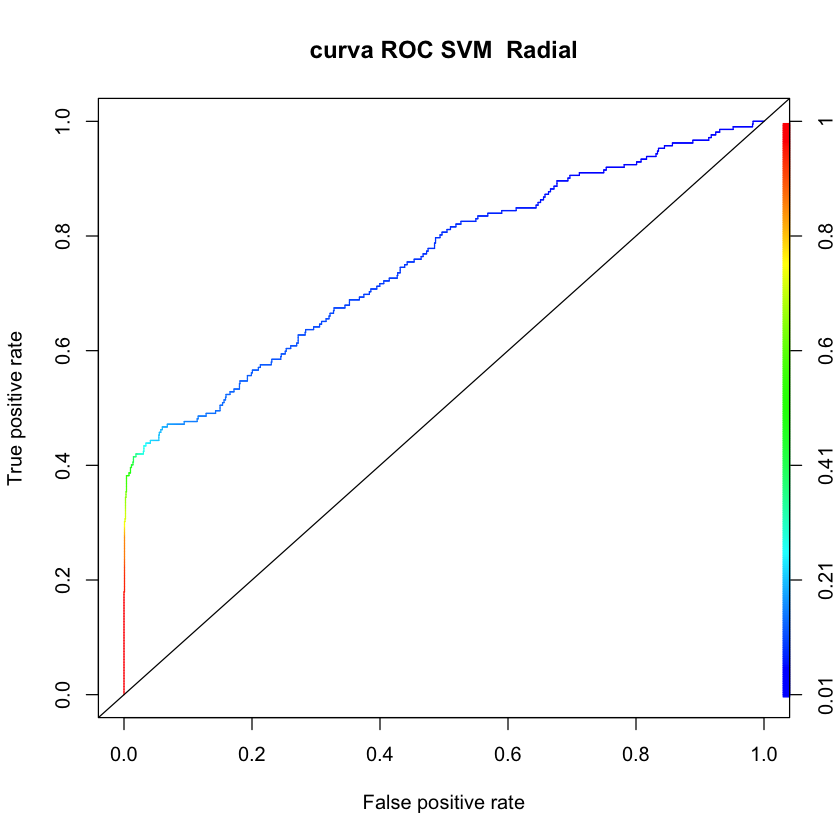

[1] "Polinomial"
     
pred    no  yes
  no  1280  129
  yes    6   83


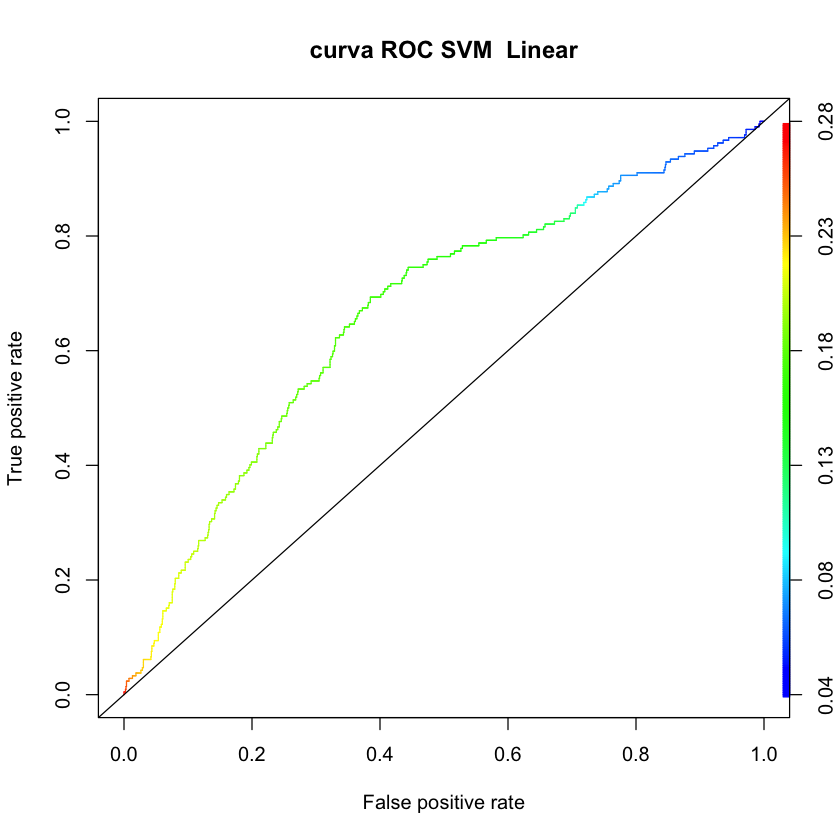

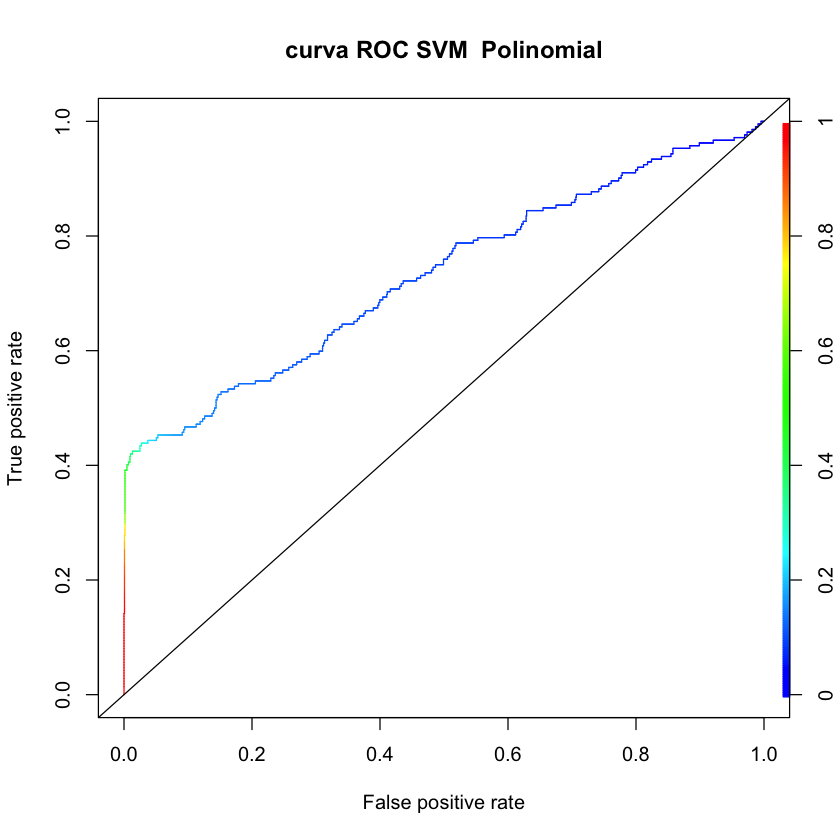

In [131]:
m_radial <- metricas_svm("Radial", svm_radial$best.model, test)
m_linear <- metricas_svm("Linear", svm_linear$best.model, test)
m_polyn <- metricas_svm("Polinomial", svm_polyn$best.model, test)

En la tabla de predicción de cada modelo SVM podemos observar variaciones en la combinación de:

-   **Verdaderos Negativos**: El modelo predice correctamente que el cliente NO cancela.

-   **Falsos Negativos**: El modelo predice que el cliente NO cancela cuando en realidad SI cancela.

-   **Falsos Positivos**: El modelo predice que el cliente SI cancela cuando en realidad NO cancela.

-   **Verdaderos Positivos**: El modelo predice correctamente que el cliente SI cancela.

A los que hay que prestarle especial antención son a:

-   **Falsos Negativos**: porque es un error costoso, son clientes que se podrían retener.

-   **Verdaderos Positivos**: porque es el objetivo principal del modelo, que pueda predecir clientes que realmente van a cancelar.

Por otro lado, analizando el gráfico ROC, observamos que todos tienen una pendiente inicial ascendente parecida y tiende a la curva ideal (se generan menos falsos positivos), hasta el 0.4, excepto el SVM Lineal que parece ser el menos indicado para este conjunto de datos.

### Comparación de métricas entre modelos

In [132]:
m_combinado <- rbind(m_modelo1, m_bayes, m_knn, m_radial, m_linear, m_polyn)
kable(m_combinado, caption = "Comparación de Métricas entre Modelos", row.names = F)



Table: Comparación de Métricas entre Modelos

|Model       |  Accuracy| Sensitivity| Specificity| Precision|  Area_ROC|
|:-----------|---------:|-----------:|-----------:|---------:|---------:|
|Regresión   | 0.8684913|   0.0707547|   1.0000000| 1.0000000| 0.6908397|
|Naive Bayes | 0.8798398|   0.3443396|   0.9681182| 0.6403509| 0.6857009|
|KNN         | 0.8905207|   0.2547170|   0.9953344| 0.9000000| 0.7349761|
|Radial      | 0.9065421|   0.3820755|   0.9930016| 0.9000000| 0.7533598|
|Linear      | 0.8584780|   0.0000000|   1.0000000|       NaN| 0.6656262|
|Polinomial  | 0.9098798|   0.3915094|   0.9953344| 0.9325843| 0.7309633|

* Se prioriza la SENSIBILIDAD cuando el costo del Falso Negativo es alto, pues se enfoca en minimizar los Falsos Negativos.
    En este caso, al predecir que un cliente NO cancelará y si lo hace, perderíamoss un cliente sin intentar retenerlo.
* Se prioriza la ESPECIFICIDAD cuando el costo del Falso Positivo es alto, pues se enfoca en minimizar los Falsos Positivos.
    En este caso, al predecir que un cliente cancelará y no lo hace, se gastan recursos en un cliente que no estaba en riesgo de irse.

* Considerando eso, si la promoción especial es muy costosa para la empresa, habría que elegir el modelo que tenga mayor Sensibilidad.
* Cabe destacar que estos modelos, al priorizar los Falsos Negativos (caso de que un cliente no cancele cuando si lo hace), puede producir que no se le haga una promoción a un potencial cliente que va a cancelar.
* El modelo elegido, para la necesidad a resolver, es el modelo SVM Polinomial con una Precisión de 90.98%, una Sensibilidad del 39.15% y una Especificidad de casi el 100%, incluso siendo el que mayor área bajo la curva ROC tiene (0.73).
* El área bajo la curva ROC cercana al 0.8 habla de un modelo con buena capacidad de discriminación.